In [4]:
%matplotlib widget

In [16]:
from standard_imports import *
from loaders import index
from plots import splt, interactive
from ModelSimlink import RadiativeTransitions, Levels
from Tools import LinesManipulator

In [12]:
data = index.load_index_and_data( "TestData/RfPen/20230620" ) + index.load_index_and_data( "TestData/PlasmaBIC/20241031" )

Avantes spectrum TestData/RfPen/20230620\New Experiment0005.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0006.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0007.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0008.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0013.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0014.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0015.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0016.Raw8 normalized by a factor of 0.200000 s
8 rows loaded
Avantes spectrum TestData/PlasmaBIC/20241031\101_6us.RAW8 normalized by a factor of 0.400000 s
Avantes spectrum TestData/PlasmaBIC/20241031\102_6us.RAW8 normalized by a f

In [13]:
worker = LinesManipulator.LinesManipulator()

In [14]:
calib_base = pd.read_csv('CalibrationData/Calib_20250204_FCUVIR600.csv', index_col = False).to_dict('list')

In [17]:
for d in data:
        d['wl_realigned'] = worker.realign_wl( d['avantes']['wl'], d['avantes']['int'] )
        d['int_withoutbaseline'] = worker.remove_baseline( d['avantes']['int'] )
        d['cal'] = worker.estimate_calibration( d['wl_realigned'], d['int_withoutbaseline'], calib_base, all_lines = RadiativeTransitions.RadiativeTransitions().linesList() )
        d['int_calibrated'] = d['cal']['int_calib']

Realigned with y = -0.00x^2 +1.00x -0.26
Initializing class Levels
Realigned with y = -0.00x^2 +1.00x -0.22
Realigned with y = -0.00x^2 +1.00x -0.19
Realigned with y = 0.00x^2 +1.00x -0.10
Realigned with y = -0.00x^2 +1.00x -0.18
Realigned with y = 0.00x^2 +1.00x -0.15
Realigned with y = -0.00x^2 +1.00x -0.16
Realigned with y = 0.00x^2 +1.00x -0.12
Realigned with y = 0.00x^2 +1.00x +0.96
Realigned with y = 0.00x^2 +1.00x +1.33
Realigned with y = 0.00x^2 +1.00x +1.24
Realigned with y = 0.00x^2 +1.00x +0.91
Realigned with y = 0.00x^2 +1.00x +0.90
Realigned with y = 0.00x^2 +1.00x +1.24
Realigned with y = 0.00x^2 +1.00x +0.99
Realigned with y = 0.00x^2 +1.00x +0.99
Realigned with y = 0.00x^2 +1.00x +1.17
Realigned with y = 0.00x^2 +1.00x +0.94
Realigned with y = -0.00x^2 +1.00x +0.21
Realigned with y = -0.00x^2 +1.00x +0.45


(650.0, 980.0)

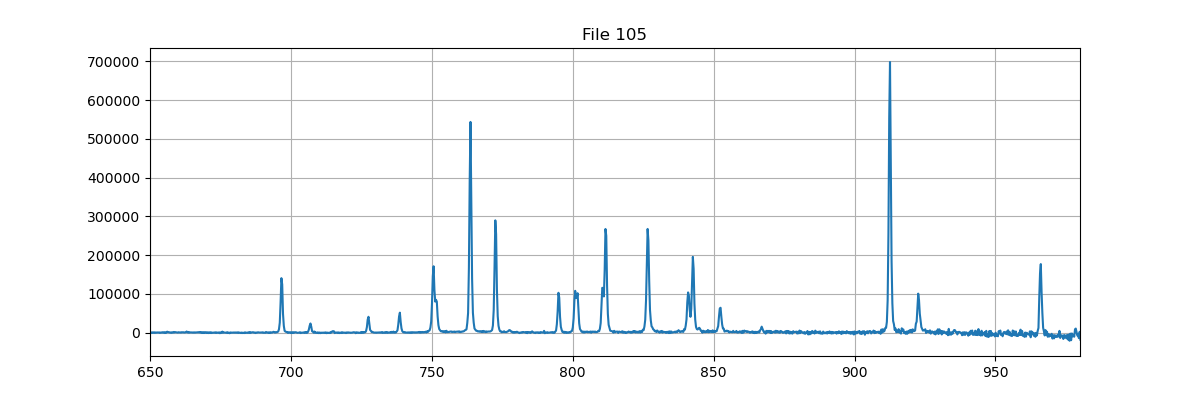

In [22]:
POS = 12
d = data[POS]
splt.init( size = (12,4))
plt.plot( d['wl_realigned'], d['int_calibrated'] )
plt.title(f"File {d['ID']}")
plt.xlim( 650, 980 )